<a href="https://colab.research.google.com/github/Lalangari/CS316-Project-Solar-Power-Forecasting/blob/main/CS316_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Prince Sultan University
###College of Computer and Information Systems


###CS316 Project: Solar Power Forecasting

**Section #:** 1282
**Instructor:** Dr. Heyfa Ammar


- Rozana Aljudhy  222511292
- Deema Alqahtani  223410073
- Lama Alangari  222410037
- Layan Alagel  222410696

In [1]:
#imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score
import seaborn as sns
from IPython.display import display
from xgboost import XGBRegressor
from sklearn.ensemble import RandomForestRegressor

In [2]:
import pandas as pd

# Load the four dataset files directly from the project repository.
# Original source: Kaggle, Solar Power Generation Data
base = "https://raw.githubusercontent.com/Lalangari/CS316-Project-Solar-Power-Forecasting/main/data/"

# Plant 1 generation and weather readings
plant1_generation = pd.read_csv(base + "Plant_1_Generation_Data.csv")
plant1_weather    = pd.read_csv(base + "Plant_1_Weather_Sensor_Data.csv")

# Plant 2 generation and weather readings
plant2_generation = pd.read_csv(base + "Plant_2_Generation_Data.csv")
plant2_weather    = pd.read_csv(base + "Plant_2_Weather_Sensor_Data.csv")

print("All files loaded successfully")

All files loaded successfully


In [3]:
# Check the size (rows, columns) of each dataframe

print("Plant 1 Generation:", plant1_generation.shape)
print("Plant 1 Weather:", plant1_weather.shape)
print("Plant 2 Generation:", plant2_generation.shape)
print("Plant 2 Weather:", plant2_weather.shape)

Plant 1 Generation: (68778, 7)
Plant 1 Weather: (3182, 6)
Plant 2 Generation: (67698, 7)
Plant 2 Weather: (3259, 6)


In [4]:
# List the column names of each file to see which variables are available

print("Plant 1 Generation columns:")
print(plant1_generation.columns.tolist())

print("\nPlant 1 Weather columns:")
print(plant1_weather.columns.tolist())

print("\nPlant 2 Generation columns:")
print(plant2_generation.columns.tolist())

print("\nPlant 2 Weather columns:")
print(plant2_weather.columns.tolist())

Plant 1 Generation columns:
['DATE_TIME', 'PLANT_ID', 'SOURCE_KEY', 'DC_POWER', 'AC_POWER', 'DAILY_YIELD', 'TOTAL_YIELD']

Plant 1 Weather columns:
['DATE_TIME', 'PLANT_ID', 'SOURCE_KEY', 'AMBIENT_TEMPERATURE', 'MODULE_TEMPERATURE', 'IRRADIATION']

Plant 2 Generation columns:
['DATE_TIME', 'PLANT_ID', 'SOURCE_KEY', 'DC_POWER', 'AC_POWER', 'DAILY_YIELD', 'TOTAL_YIELD']

Plant 2 Weather columns:
['DATE_TIME', 'PLANT_ID', 'SOURCE_KEY', 'AMBIENT_TEMPERATURE', 'MODULE_TEMPERATURE', 'IRRADIATION']


In [5]:
# Count Null values per column

print("Plant 1 Generation:")
print(plant1_generation.isnull().sum())

print("\nPlant 1 Weather:")
print(plant1_weather.isnull().sum())

print("\nPlant 2 Generation:")
print(plant2_generation.isnull().sum())

print("\nPlant 2 Weather:")
print(plant2_weather.isnull().sum())

Plant 1 Generation:
DATE_TIME      0
PLANT_ID       0
SOURCE_KEY     0
DC_POWER       0
AC_POWER       0
DAILY_YIELD    0
TOTAL_YIELD    0
dtype: int64

Plant 1 Weather:
DATE_TIME              0
PLANT_ID               0
SOURCE_KEY             0
AMBIENT_TEMPERATURE    0
MODULE_TEMPERATURE     0
IRRADIATION            0
dtype: int64

Plant 2 Generation:
DATE_TIME      0
PLANT_ID       0
SOURCE_KEY     0
DC_POWER       0
AC_POWER       0
DAILY_YIELD    0
TOTAL_YIELD    0
dtype: int64

Plant 2 Weather:
DATE_TIME              0
PLANT_ID               0
SOURCE_KEY             0
AMBIENT_TEMPERATURE    0
MODULE_TEMPERATURE     0
IRRADIATION            0
dtype: int64


In [6]:
# Preview the first rows of the Plant 1 generation data
# DATE_TIME is still text here in DD-MM-YYYY HH:MM format
display(plant1_generation.head())

,DATE_TIME,PLANT_ID,SOURCE_KEY,DC_POWER,AC_POWER,DAILY_YIELD,TOTAL_YIELD
0,15-05-2020 00:00,4135001,1BY6WEcLGh8j5v7,0.0,0.0,0.0,6259559.0
1,15-05-2020 00:00,4135001,1IF53ai7Xc0U56Y,0.0,0.0,0.0,6183645.0
2,15-05-2020 00:00,4135001,3PZuoBAID5Wc2HD,0.0,0.0,0.0,6987759.0
3,15-05-2020 00:00,4135001,7JYdWkrLSPkdwr4,0.0,0.0,0.0,7602960.0
4,15-05-2020 00:00,4135001,McdE0feGgRqW7Ca,0.0,0.0,0.0,7158964.0


In [7]:
# Preview the first rows of the Plant 1 weather data
# DATE_TIME uses a different format (YYYY-MM-DD HH:MM:SS) from the generation file
display(plant1_weather.head())

,DATE_TIME,PLANT_ID,SOURCE_KEY,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION
0,2020-05-15 00:00:00,4135001,HmiyD2TTLFNqkNe,25.184316,22.857507,0.0
1,2020-05-15 00:15:00,4135001,HmiyD2TTLFNqkNe,25.084589,22.761668,0.0
2,2020-05-15 00:30:00,4135001,HmiyD2TTLFNqkNe,24.935753,22.592306,0.0
3,2020-05-15 00:45:00,4135001,HmiyD2TTLFNqkNe,24.846130,22.360852,0.0
4,2020-05-15 01:00:00,4135001,HmiyD2TTLFNqkNe,24.621525,22.165423,0.0


In [8]:
# Convert date columns to datetime
# dayfirst=True because Plant 1 writes dates as DD-MM-YYYY
plant1_generation["DATE_TIME"] = pd.to_datetime(
    plant1_generation["DATE_TIME"],
    dayfirst=True
)

# Weather files are already in YYYY-MM-DD HH:MM:SS, which pandas reads without help

plant1_weather["DATE_TIME"] = pd.to_datetime(
    plant1_weather["DATE_TIME"]
)

# Plant 2 generation is in YYYY-MM-DD format, so dayfirst=True triggers a warning

plant2_generation["DATE_TIME"] = pd.to_datetime(
    plant2_generation["DATE_TIME"],
    dayfirst=True
)

plant2_weather["DATE_TIME"] = pd.to_datetime(
    plant2_weather["DATE_TIME"]
)

# Confirm all four files cover the same period

print("Plant 1 Generation:",
      plant1_generation["DATE_TIME"].min(),
      "to",
      plant1_generation["DATE_TIME"].max())

print("Plant 1 Weather:",
      plant1_weather["DATE_TIME"].min(),
      "to",
      plant1_weather["DATE_TIME"].max())

print("Plant 2 Generation:",
      plant2_generation["DATE_TIME"].min(),
      "to",
      plant2_generation["DATE_TIME"].max())

print("Plant 2 Weather:",
      plant2_weather["DATE_TIME"].min(),
      "to",
      plant2_weather["DATE_TIME"].max())

Plant 1 Generation: 2020-05-15 00:00:00 to 2020-06-17 23:45:00
Plant 1 Weather: 2020-05-15 00:00:00 to 2020-06-17 23:45:00
Plant 2 Generation: 2020-05-15 00:00:00 to 2020-06-17 23:45:00
Plant 2 Weather: 2020-05-15 00:00:00 to 2020-06-17 23:45:00


/tmp/ipykernel_11697/2043010619.py:16: UserWarning: Parsing dates in %Y-%m-%d %H:%M:%S format when dayfirst=True was specified. Pass `dayfirst=False` or specify a format to silence this warning.
  plant2_generation["DATE_TIME"] = pd.to_datetime(


In [9]:
# Plant 1 generation: DD-MM-YYYY HH:MM
plant1_generation["DATE_TIME"] = pd.to_datetime(
    plant1_generation["DATE_TIME"], format="%d-%m-%Y %H:%M"
)

# Plant 1 weather: YYYY-MM-DD HH:MM:SS
plant1_weather["DATE_TIME"] = pd.to_datetime(
    plant1_weather["DATE_TIME"], format="%Y-%m-%d %H:%M:%S"
)

# Plant 2 generation: check format first
print(plant2_generation["DATE_TIME"].head())

0   2020-05-15
1   2020-05-15
2   2020-05-15
3   2020-05-15
4   2020-05-15
Name: DATE_TIME, dtype: datetime64[ns]


In [10]:
# Plant 2 generation: YYYY-MM-DD HH:MM:SS
plant2_generation["DATE_TIME"] = pd.to_datetime(
    plant2_generation["DATE_TIME"], format="%Y-%m-%d %H:%M:%S"
)

# Plant 2 weather: YYYY-MM-DD HH:MM:SS
plant2_weather["DATE_TIME"] = pd.to_datetime(
    plant2_weather["DATE_TIME"], format="%Y-%m-%d %H:%M:%S"
)

# confirm all four are proper datetime now
for name, df in [("plant1_generation", plant1_generation),
                  ("plant1_weather", plant1_weather),
                  ("plant2_generation", plant2_generation),
                  ("plant2_weather", plant2_weather)]:
    print(name, df["DATE_TIME"].dtype)

plant1_generation datetime64[ns]
plant1_weather datetime64[ns]
plant2_generation datetime64[ns]
plant2_weather datetime64[ns]


In [11]:
# Merge generation data with weather data for each plant
# Every 15-minute slot in the study period (used to spot and fill gaps in the weather data)

full_grid = pd.date_range("2020-05-15 00:00", "2020-06-17 23:45", freq="15min")
weather_cols = ["AMBIENT_TEMPERATURE", "MODULE_TEMPERATURE", "IRRADIATION"]

def fill_weather(weather):
    # Index by time, add the missing slots, fill them from the readings on either side
    return (weather.set_index("DATE_TIME")[weather_cols]
            .reindex(full_grid)
            .interpolate(method="time")
            .rename_axis("DATE_TIME")
            .reset_index())

# Merge generation with the gap-filled weather
plant1 = plant1_generation.merge(fill_weather(plant1_weather), on="DATE_TIME", how="left")
plant2 = plant2_generation.merge(fill_weather(plant2_weather), on="DATE_TIME", how="left")

# Check the merge kept every generation row and left no missing weather values
print("Plant 1:", plant1.shape, "| nulls:", int(plant1.isnull().sum().sum()))
print("Plant 2:", plant2.shape, "| nulls:", int(plant2.isnull().sum().sum()))

Plant 1: (68778, 10) | nulls: 0
Plant 2: (67698, 10) | nulls: 0


In [12]:
# Combine both plants into one dataframe
# Tag each row with its plant first, because PLANT_ID is a long number that is hard to read

plant1["PLANT_LABEL"] = "Plant_1"
plant2["PLANT_LABEL"] = "Plant_2"

# Stack the two dataframes
solar_data = pd.concat([plant1, plant2], ignore_index=True)

# Check the row counts
print("Combined shape:", solar_data.shape)
print(solar_data["PLANT_LABEL"].value_counts())
solar_data.head()

Combined shape: (136476, 11)
PLANT_LABEL
Plant_1    68778
Plant_2    67698
Name: count, dtype: int64


,DATE_TIME,PLANT_ID,SOURCE_KEY,DC_POWER,AC_POWER,DAILY_YIELD,TOTAL_YIELD,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION,PLANT_LABEL
0,2020-05-15,4135001,1BY6WEcLGh8j5v7,0.0,0.0,0.0,6259559.0,25.184316,22.857507,0.0,Plant_1
1,2020-05-15,4135001,1IF53ai7Xc0U56Y,0.0,0.0,0.0,6183645.0,25.184316,22.857507,0.0,Plant_1
2,2020-05-15,4135001,3PZuoBAID5Wc2HD,0.0,0.0,0.0,6987759.0,25.184316,22.857507,0.0,Plant_1
3,2020-05-15,4135001,7JYdWkrLSPkdwr4,0.0,0.0,0.0,7602960.0,25.184316,22.857507,0.0,Plant_1
4,2020-05-15,4135001,McdE0feGgRqW7Ca,0.0,0.0,0.0,7158964.0,25.184316,22.857507,0.0,Plant_1


In [13]:
# extract time-based features from the DATE_TIME column
solar_data["HOUR"] = solar_data["DATE_TIME"].dt.hour
solar_data["MINUTE"] = solar_data["DATE_TIME"].dt.minute
solar_data["DAY"] = solar_data["DATE_TIME"].dt.day
solar_data["MONTH"] = solar_data["DATE_TIME"].dt.month
solar_data["DAY_OF_WEEK"] = solar_data["DATE_TIME"].dt.dayofweek
solar_data["DAY_OF_YEAR"] = solar_data["DATE_TIME"].dt.dayofyear

# Preview the new columns next to the original timestamp
solar_data[["DATE_TIME", "HOUR", "MINUTE", "DAY", "MONTH", "DAY_OF_WEEK", "DAY_OF_YEAR"]].head()

,DATE_TIME,HOUR,MINUTE,DAY,MONTH,DAY_OF_WEEK,DAY_OF_YEAR
0,2020-05-15,0,0,15,5,4,136
1,2020-05-15,0,0,15,5,4,136
2,2020-05-15,0,0,15,5,4,136
3,2020-05-15,0,0,15,5,4,136
4,2020-05-15,0,0,15,5,4,136


In [14]:
# how much hotter the panel is than the surrounding air
# Hotter panels convert sunlight less efficiently, so this may help explain output
solar_data["TEMP_DIFFERENCE"] = solar_data["MODULE_TEMPERATURE"] - solar_data["AMBIENT_TEMPERATURE"]

In [15]:
print(solar_data.isnull().sum().sum(), "total nulls")
print(solar_data.dtypes)
print(solar_data.shape)
print(solar_data.columns.tolist())

# Save the cleaned dataset
solar_data.to_csv("solar_data_cleaned.csv", index=False)
print("Saved: solar_data_cleaned.csv")

0 total nulls
DATE_TIME              datetime64[ns]
PLANT_ID                        int64
SOURCE_KEY                     object
DC_POWER                      float64
AC_POWER                      float64
DAILY_YIELD                   float64
TOTAL_YIELD                   float64
AMBIENT_TEMPERATURE           float64
MODULE_TEMPERATURE            float64
IRRADIATION                   float64
PLANT_LABEL                    object
HOUR                            int32
MINUTE                          int32
DAY                             int32
MONTH                           int32
DAY_OF_WEEK                     int32
DAY_OF_YEAR                     int32
TEMP_DIFFERENCE               float64
dtype: object
(136476, 18)
['DATE_TIME', 'PLANT_ID', 'SOURCE_KEY', 'DC_POWER', 'AC_POWER', 'DAILY_YIELD', 'TOTAL_YIELD', 'AMBIENT_TEMPERATURE', 'MODULE_TEMPERATURE', 'IRRADIATION', 'PLANT_LABEL', 'HOUR', 'MINUTE', 'DAY', 'MONTH', 'DAY_OF_WEEK', 'DAY_OF_YEAR', 'TEMP_DIFFERENCE']
Saved: solar_data_clean

In [16]:
#measure memory, shrink the data types, then measure again
before_mb = solar_data.memory_usage(deep=True).sum() / 1e6

#store each distinct ID once as a category
solar_data["SOURCE_KEY"] = solar_data["SOURCE_KEY"].astype("category")

#float64 to float32 (about 7 significant digits, enough for these measurements)
for col in solar_data.select_dtypes("float64").columns:
    solar_data[col] = pd.to_numeric(solar_data[col], downcast="float")

solar_data["PLANT_ID"] = solar_data["PLANT_ID"].astype("int32")

after_mb = solar_data.memory_usage(deep=True).sum() / 1e6
print(f"{before_mb:.1f} MB -> {after_mb:.1f} MB ({100 * (1 - after_mb / before_mb):.0f}% smaller)")

30.6 MB -> 17.6 MB (42% smaller)


In [17]:
# create a copy of the caleaned dataset for exploraty analysis. select AC power, irradiation, ambient temperature, and module temperature for analysis.


sns.set_theme(style="whitegrid")

# Copy the cleaned data
eda_data = solar_data.copy()

features = [
    "AC_POWER",
    "IRRADIATION",
    "AMBIENT_TEMPERATURE",
    "MODULE_TEMPERATURE"
]

In [18]:
# Descriptive statistics for each plant
#Present the descriptive statistics for every plant, such as the count, average, standard deviation, minimum, maximum, and quartiles of the chosen variables.

for plant, data in eda_data.groupby("PLANT_LABEL"):
    print(f"\n{plant}: Descriptive Statistics")
    display(data[features].describe().round(2))


Plant_1: Descriptive Statistics


,AC_POWER,IRRADIATION,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE
count,68778.00,68778.00,68778.00,68778.00
mean,307.80,0.23,25.56,31.25
std,394.45,0.30,3.36,12.31
min,0.00,0.00,20.40,18.14
25%,0.00,0.00,22.72,21.12
50%,41.49,0.03,24.67,24.82
75%,623.62,0.45,27.96,41.69
max,1410.95,1.22,35.25,65.55



Plant_2: Descriptive Statistics


,AC_POWER,IRRADIATION,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE
count,67698.00,67698.00,67698.00,67698.00
mean,241.28,0.23,27.99,32.61
std,362.17,0.31,4.02,11.23
min,0.00,0.00,20.94,20.27
25%,0.00,0.00,24.57,23.69
50%,0.00,0.02,26.91,27.43
75%,438.22,0.43,30.91,40.02
max,1385.42,1.10,39.18,66.64


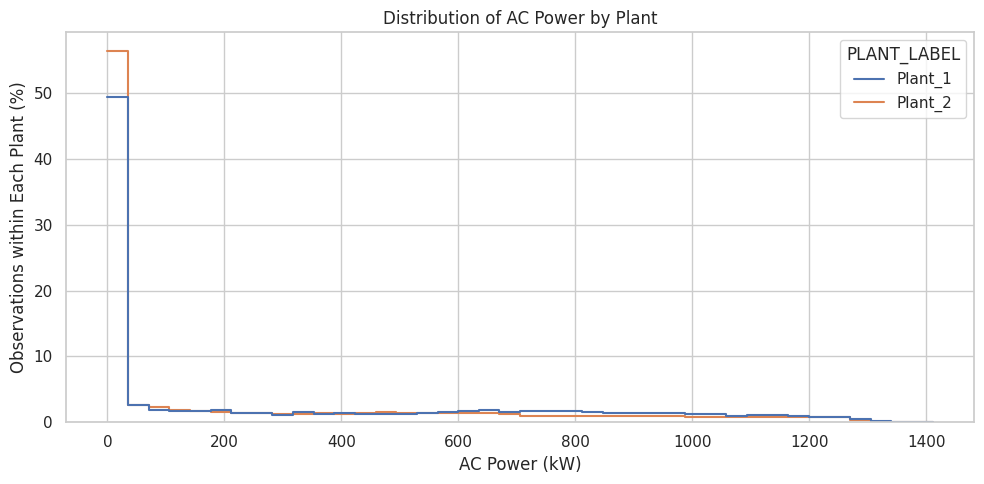

In [19]:
# Distribution of AC power
#Illustrate the distribution of inverter AC energy for both facilities. Each plant has percentages calculated individually to facilitate comparison among datasets of varying sizes.

plt.figure(figsize=(10, 5))

sns.histplot(
    data=eda_data,
    x="AC_POWER",
    hue="PLANT_LABEL",
    bins=40,
    stat="percent",
    common_norm=False,
    element="step",
    fill=False
)

plt.title("Distribution of AC Power by Plant")
plt.xlabel("AC Power (kW)")
plt.ylabel("Observations within Each Plant (%)")
plt.tight_layout()
plt.show()

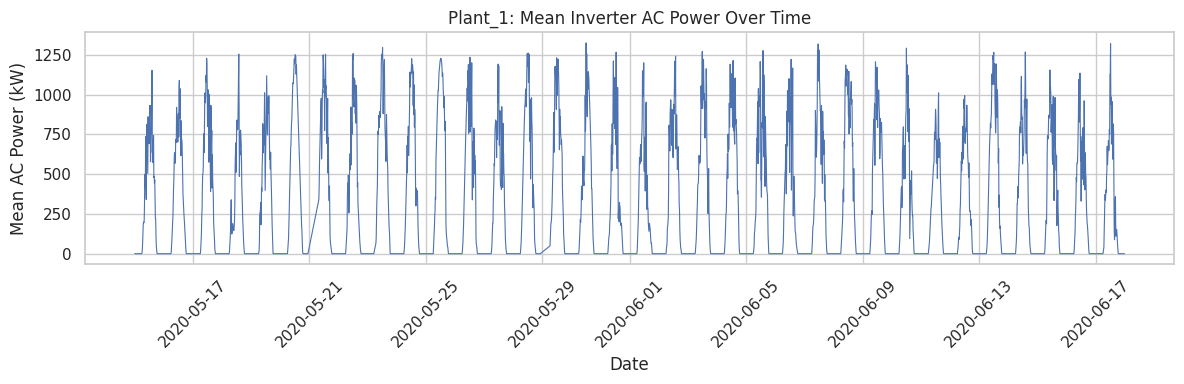

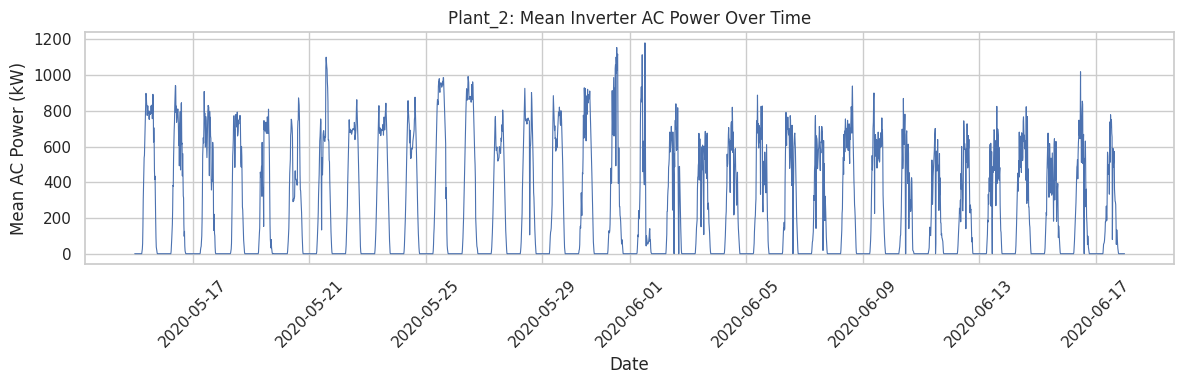

In [20]:
# Calculate mean inverter AC power at each timestamp
#Compute and graph the average AC power for all available inverters at each time point for every plant. These graphs illustrate variations in mean inverter output throughout the observation period.

power_over_time = (
    eda_data.groupby(["PLANT_LABEL", "DATE_TIME"])["AC_POWER"]
    .mean()
    .reset_index()
    .sort_values(["PLANT_LABEL", "DATE_TIME"])
)

for plant, data in power_over_time.groupby("PLANT_LABEL"):
    plt.figure(figsize=(12, 4))

    plt.plot(
        data["DATE_TIME"],
        data["AC_POWER"],
        linewidth=0.8
    )

    plt.title(f"{plant}: Mean Inverter AC Power Over Time")
    plt.xlabel("Date")
    plt.ylabel("Mean AC Power (kW)")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

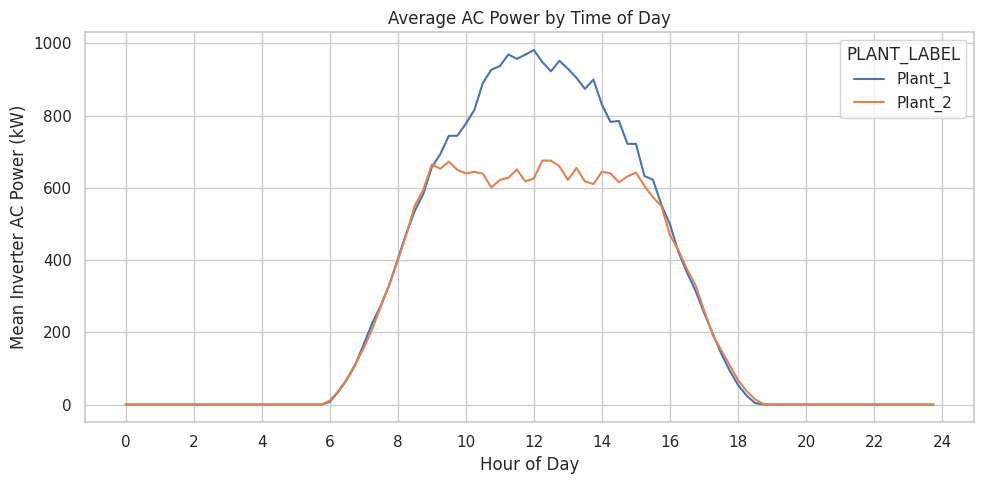

In [21]:
# Calculate the time of day
#Determine the mean inverter AC power at different times throughout the observation duration. Analyze the daily output trends of the two facilities.

power_over_time["HOUR_OF_DAY"] = (
    power_over_time["DATE_TIME"].dt.hour
    + power_over_time["DATE_TIME"].dt.minute / 60
)

# Calculate average power for each time of day

daily_pattern = (
    power_over_time.groupby(
        ["PLANT_LABEL", "HOUR_OF_DAY"]
    )["AC_POWER"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(10, 5))

sns.lineplot(
    data=daily_pattern,
    x="HOUR_OF_DAY",
    y="AC_POWER",
    hue="PLANT_LABEL"
)

plt.title("Average AC Power by Time of Day")
plt.xlabel("Hour of Day")
plt.ylabel("Mean Inverter AC Power (kW)")
plt.xticks(range(0, 25, 2))
plt.tight_layout()
plt.show()

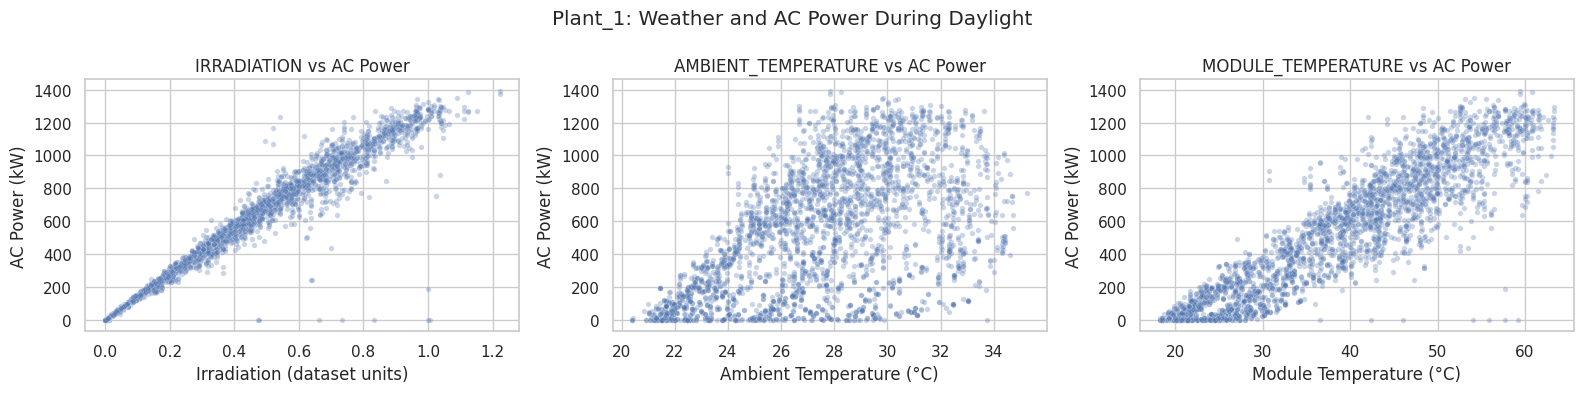

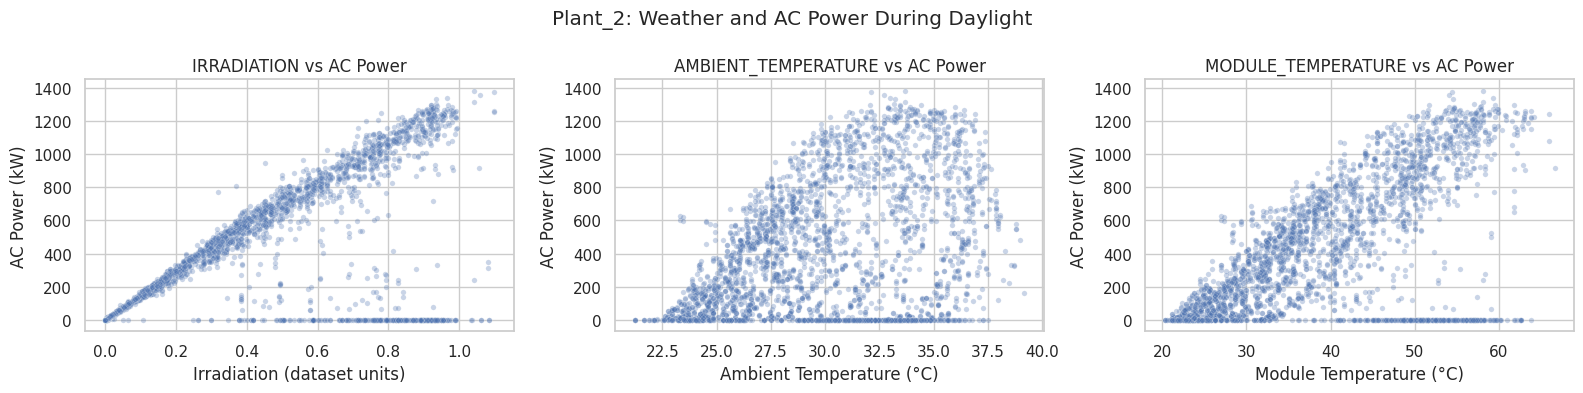

In [22]:
# Select daylight observations
#Examine the connections among AC power, irradiation, ambient temperature, and module temperature by utilizing daylight data when irradiation exceeds zero. Generate a reproducible sample with a maximum of 3,000 observations per plant to minimize overlap.

daylight_data = eda_data[
    eda_data["IRRADIATION"] > 0
].copy()

weather_features = [
    "IRRADIATION",
    "AMBIENT_TEMPERATURE",
    "MODULE_TEMPERATURE"
]

axis_labels = {
    "IRRADIATION": "Irradiation (dataset units)",
    "AMBIENT_TEMPERATURE": "Ambient Temperature (°C)",
    "MODULE_TEMPERATURE": "Module Temperature (°C)"
}

for plant, data in daylight_data.groupby("PLANT_LABEL"):

    # Sample points to make the plots easier to read
    sample_data = data.sample(
        n=min(3000, len(data)),
        random_state=42
    )

    fig, axes = plt.subplots(1, 3, figsize=(16, 4))

    for ax, feature in zip(axes, weather_features):
        sns.scatterplot(
            data=sample_data,
            x=feature,
            y="AC_POWER",
            alpha=0.3,
            s=15,
            ax=ax
        )

        ax.set_title(f"{feature} vs AC Power")
        ax.set_xlabel(axis_labels[feature])
        ax.set_ylabel("AC Power (kW)")

    fig.suptitle(
        f"{plant}: Weather and AC Power During Daylight"
    )

    plt.tight_layout()
    plt.show()

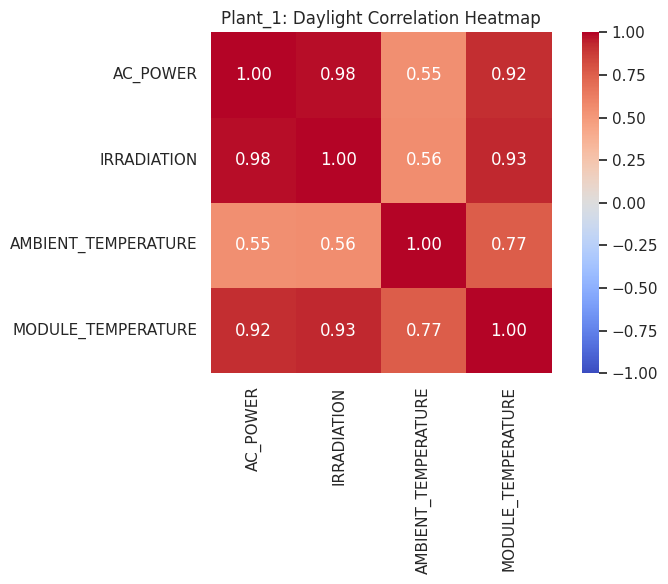


Plant_1: Correlations with AC Power


,Correlation with AC_POWER
IRRADIATION,0.980
MODULE_TEMPERATURE,0.917
AMBIENT_TEMPERATURE,0.551


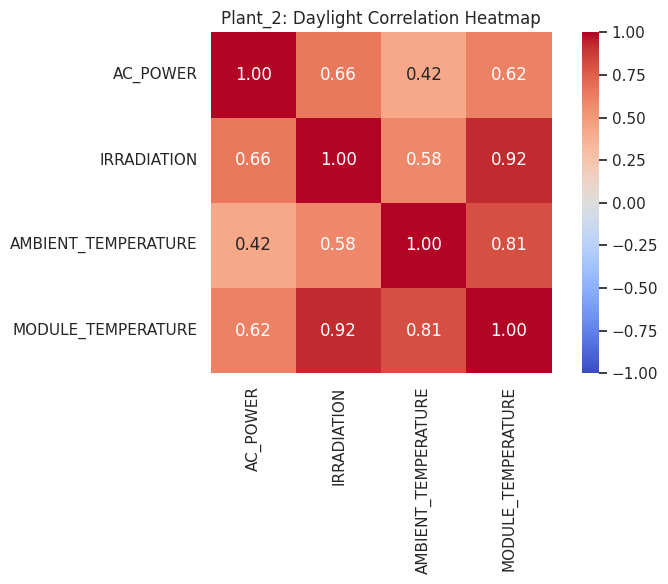


Plant_2: Correlations with AC Power


,Correlation with AC_POWER
IRRADIATION,0.656
MODULE_TEMPERATURE,0.615
AMBIENT_TEMPERATURE,0.423


In [23]:
# Correlation heatmap for each plant
#Compute Pearson correlations utilizing all daylight measurements for each plant. Show heatmaps and the relationships between weather variables and AC power. Values near +1 or -1 suggest strong linear correlations, whereas values near zero imply weak linear correlations. Correlation does not imply causation.

for plant, data in daylight_data.groupby("PLANT_LABEL"):

    correlation = data[features].corr()

    plt.figure(figsize=(8, 6))

    sns.heatmap(
        correlation,
        annot=True,
        fmt=".2f",
        cmap="coolwarm",
        vmin=-1,
        vmax=1,
        square=True
    )

    plt.title(f"{plant}: Daylight Correlation Heatmap")
    plt.tight_layout()
    plt.show()

    print(f"\n{plant}: Correlations with AC Power")

    display(
        correlation["AC_POWER"]
        .drop("AC_POWER")
        .sort_values(ascending=False)
        .round(3)
        .to_frame(name="Correlation with AC_POWER")
    )

In [24]:

# MODEL TRAINING


# XGBoost vs Random Forest Regressor

!pip -q install xgboost



from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

#1 Prepare the dataset


model_data = solar_data.copy()

# Convert timestamp into datetime
model_data["DATE_TIME"] = pd.to_datetime(
    model_data["DATE_TIME"]
)

# Create temperature difference feature
model_data["TEMP_DIFFERENCE"] = (
    model_data["MODULE_TEMPERATURE"]
    - model_data["AMBIENT_TEMPERATURE"]
)

# Remove records without the target value
model_data = model_data.dropna(subset=["AC_POWER"])

# Sort chronologically
model_data = model_data.sort_values("DATE_TIME")

#2 Select input features and target

features = [
    "IRRADIATION",
    "AMBIENT_TEMPERATURE",
    "MODULE_TEMPERATURE",
    "TEMP_DIFFERENCE",
    "HOUR",
    "MINUTE",
    "DAY_OF_YEAR",
    "PLANT_LABEL",
    "SOURCE_KEY"
]

# Convert inverter identifiers to categories
model_data["SOURCE_KEY"] = (
    model_data["SOURCE_KEY"].astype(str)
)

# Convert categorical features into numbers
X = pd.get_dummies(
    model_data[features],
    columns=["PLANT_LABEL", "SOURCE_KEY"],
    dtype=int
)

# Target: solar electricity output
y = model_data["AC_POWER"]


#3 Split training and testing data

# Earlier 80% of timestamps for training
# Later 20% for testing

timestamps = model_data["DATE_TIME"].unique()

split_date = timestamps[
    int(len(timestamps) * 0.8)
]

train_mask = model_data["DATE_TIME"] < split_date
test_mask = model_data["DATE_TIME"] >= split_date

X_train = X.loc[train_mask].copy()
X_test = X.loc[test_mask].copy()

y_train = y.loc[train_mask]
y_test = y.loc[test_mask]

# Fill missing inputs using training medians
medians = X_train.median()

X_train = X_train.fillna(medians)
X_test = X_test.fillna(medians)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))



Training rows: 107788
Testing rows: 28688


In [25]:
# Train Model 1 XGBoost

model1 = XGBRegressor(
    n_estimators=400,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

model1.fit(X_train, y_train)

# Make predictions
y_pred_model1 = model1.predict(X_test)

print("XGBoost trained successfully!")

#5 Train Model 2  Random Forest

model2 = RandomForestRegressor(
    n_estimators=150,
    max_depth=16,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

model2.fit(X_train, y_train)

# Make predictions
y_pred_model2 = model2.predict(X_test)

print("Random Forest trained successfully!")


#6 Evaluate both models


def evaluate_model(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)

    return {
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2": r2
    }

results = pd.DataFrame({
    "XGBoost": evaluate_model(
        y_test, y_pred_model1
    ),
    "Random Forest": evaluate_model(
        y_test, y_pred_model2
    )
})

print("\nMODEL PERFORMANCE COMPARISON")
display(results.round(3))


#7 Identify the best model

best_model = results.loc["RMSE"].idxmin()

print("\nBest model based on RMSE:", best_model)

XGBoost trained successfully!
Random Forest trained successfully!

MODEL PERFORMANCE COMPARISON


,XGBoost,Random Forest
MAE,41.371,41.280
MSE,16453.201,16360.293
RMSE,128.270,127.907
R2,0.846,0.846



Best model based on RMSE: Random Forest


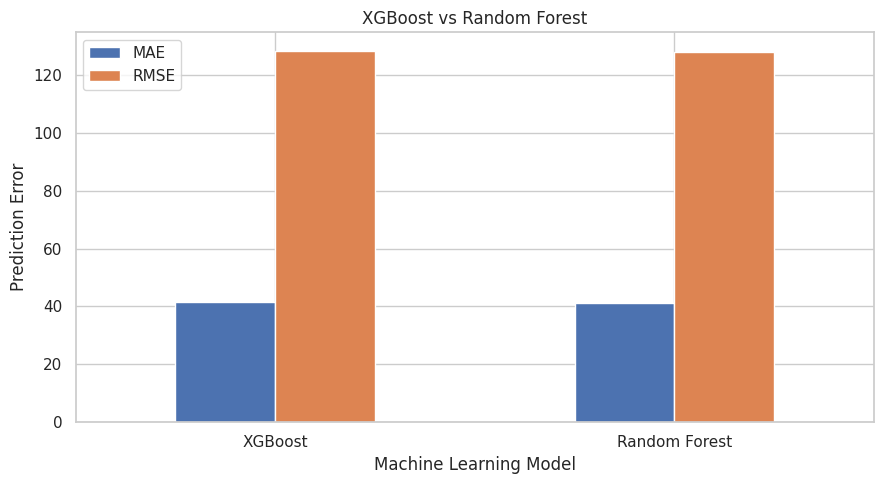

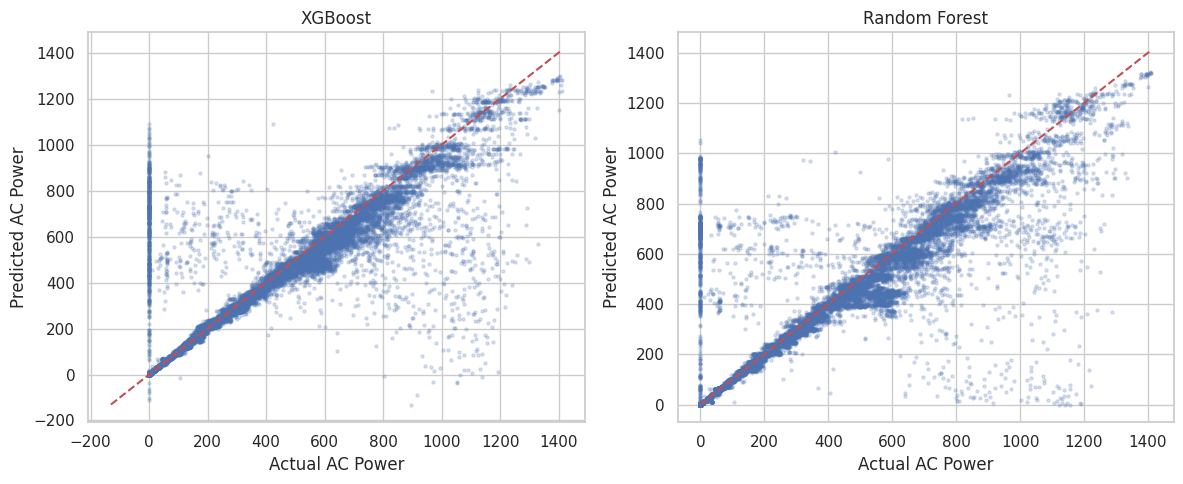

In [26]:
#8 Visualize model comparison

# Lower error values indicate better prediction performance
results.loc[["MAE", "RMSE"]].T.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("XGBoost vs Random Forest")
plt.xlabel("Machine Learning Model")
plt.ylabel("Prediction Error")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


#9 Actual vs Predicted
# Points closer to the diagonal indicate more accurate predictions

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, predictions, name in zip(
    axes,
    [y_pred_model1, y_pred_model2],
    ["XGBoost", "Random Forest"]
):
    ax.scatter(
        y_test,
        predictions,
        alpha=0.2,
        s=5
    )

   # Draw a reference line representing perfect predictions
    limits = [
        min(y_test.min(), predictions.min()),
        max(y_test.max(), predictions.max())
    ]

    ax.plot(limits, limits, "r--")

    ax.set_title(name)
    ax.set_xlabel("Actual AC Power")
    ax.set_ylabel("Predicted AC Power")

plt.tight_layout()
plt.show()

In [27]:
# Read the stored r2 and check whether each model reaches the R2 reaches 80%
r2_xgb = results.loc["R2", "XGBoost"]
r2_rf = results.loc["R2", "Random Forest"]

# R2 measures explained variation, not classification accuracy
for name, r2 in [("XGBoost", r2_xgb), ("Random Forest", r2_rf)]:
    status = "reaches" if r2 >= 0.80 else "does NOT reach"
    print(f"{name} R2 = {r2:.3f} and {status} the 0.80 threshold")


XGBoost R2 = 0.846 and reaches the 0.80 threshold
Random Forest R2 = 0.846 and reaches the 0.80 threshold


In [28]:
#Daylight only performace

# Evaluate the models during daylight when irradiation is positive
# This excludes nighttime observations that are often easier to predict

daylight = (X_test["IRRADIATION"] > 0).values

# Calculate performance metrics for daylight observations only
daylight_results = pd.DataFrame({
    "XGBoost": evaluate_model(y_test[daylight], y_pred_model1[daylight]),
    "Random Forest": evaluate_model(y_test[daylight], y_pred_model2[daylight])
})

print("Model performance on daylight rows only:")
display(daylight_results.round(3))

# What percentage of daylight rows have zero AC power
print(f"Daylight rows with zero AC power: {(y_test[daylight] == 0).mean():.1%}")

Model performance on daylight rows only:


,XGBoost,Random Forest
MAE,70.923,71.867
MSE,28642.121,28483.074
RMSE,169.240,168.769
R2,0.739,0.740


Daylight rows with zero AC power: 8.1%


In [29]:
# Performance for each plant
plant_results = {}

for plant in ["Plant_1", "Plant_2"]:
    plant_rows = (X_test[f"PLANT_LABEL_{plant}"] == 1).values

    # Evaluate both models on this plant
    for name, pred in [("XGBoost", y_pred_model1), ("Random Forest", y_pred_model2)]:
        plant_results[(plant, name)] = evaluate_model(y_test[plant_rows], pred[plant_rows])

plant_table = pd.DataFrame(plant_results).T

print("Model performance for each plant:")
display(plant_table.round(3))

Model performance for each plant:


MAE        MSE     RMSE     R2
Plant_1 XGBoost        18.408   2461.851   49.617  0.981
        Random Forest  19.922   2918.156   54.020  0.978
Plant_2 XGBoost        64.263  30401.693  174.361  0.618
        Random Forest  62.572  29761.260  172.515  0.626

In [30]:
# Feature importance using the tree models
importance = pd.DataFrame({
    "Feature": X_train.columns,
    "XGBoost": model1.feature_importances_,
    "Random Forest": model2.feature_importances_
})

# Grouping the plant and inverter columns back into one feature each
importance["Feature"] = importance["Feature"].str.replace(
    r"^(PLANT_LABEL|SOURCE_KEY)_.*", r"\1", regex=True
)
importance = importance.groupby("Feature")[["XGBoost", "Random Forest"]].sum()

# Rank features from most to least important using random forest scores
importance = importance.sort_values(
    by="Random Forest",
    ascending=False
).reset_index()

print("Top 10 most important features:")
display(importance.head(10).round(3))

Top 10 most important features:


,Feature,XGBoost,Random Forest
0,IRRADIATION,0.236,0.889
1,SOURCE_KEY,0.357,0.030
2,DAY_OF_YEAR,0.014,0.028
3,PLANT_LABEL,0.343,0.024
4,TEMP_DIFFERENCE,0.031,0.008
5,AMBIENT_TEMPERATURE,0.005,0.008
6,MODULE_TEMPERATURE,0.007,0.007
7,HOUR,0.005,0.005
8,MINUTE,0.002,0.001


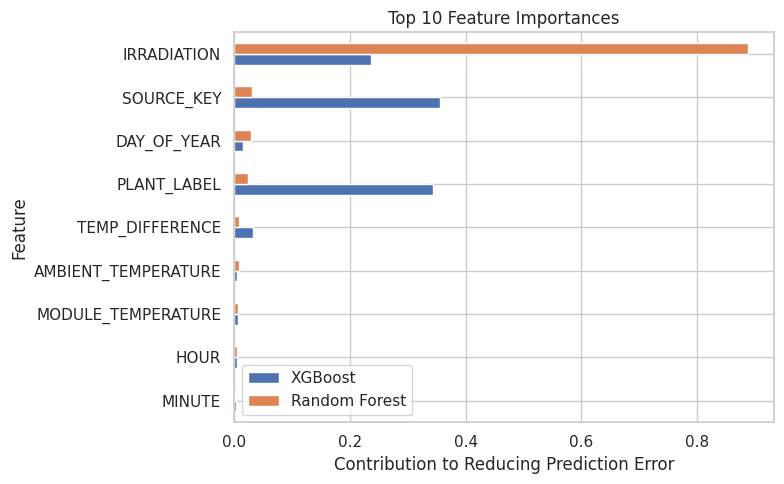

In [31]:
# Bar chart of the top 10 features for both models
importance.head(10).iloc[::-1].plot(
    kind="barh", x="Feature", y=["XGBoost", "Random Forest"], figsize=(8, 5)
)
plt.title("Top 10 Feature Importances")
plt.xlabel("Contribution to Reducing Prediction Error")
plt.tight_layout()
plt.show()